### **GPU CHECK**

In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **MOUNT DRIVE**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### **IMPORTS**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import os


### **PARAMETERS**

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15


### **DATASET PATHS**

In [ ]:
TRAIN_PATH = "/content/drive/MyDrive/dataset_final/train"
TEST_PATH  = "/content/drive/MyDrive/dataset_final/test"


### **VERIFY DATASET**

In [ ]:
print("Train folders:", os.listdir(TRAIN_PATH))
print("Test folders :", os.listdir(TEST_PATH))


Train folders: ['Very Mild Impairment', 'Mild Impairment', 'Moderate Impairment', 'No Impairment']
Test folders : ['Very Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Mild Impairment']


### **LOAD DATASET**

In [ ]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)


Found 10254 files belonging to 4 classes.
Found 1279 files belonging to 4 classes.
Classes: ['Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Very Mild Impairment']


### **PREPROCESSING**

In [ ]:
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


### **BASE CNN (EfficientNetB0)**

In [ ]:
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### **FULL MODEL**

In [ ]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

### **COMPILE**

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


### **TRAIN**

In [ ]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)


Epoch 1/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 1383s 4s/step - accuracy: 0.5971 - loss: 1.0376 - val_accuracy: 0.5934 - val_loss: 0.8793
Epoch 2/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step - accuracy: 0.7437 - loss: 0.5869 - val_accuracy: 0.6411 - val_loss: 0.7640
Epoch 3/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 41s 121ms/step - accuracy: 0.7833 - loss: 0.5070 - val_accuracy: 0.6794 - val_loss: 0.7075
Epoch 4/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.7952 - loss: 0.4716 - val_accuracy: 0.6888 - val_loss: 0.6803
Epoch 5/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 40s 124ms/step - accuracy: 0.8145 - loss: 0.4277 - val_accuracy: 0.7138 - val_loss: 0.6302
Epoch 6/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 39s 121ms/step - accuracy: 0.8214 - loss: 0.4169 - val_accuracy: 0.7287 - val_loss: 0.6142
Epoch 7/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step - accuracy: 0.8390 - loss: 0.3785 - val_accuracy: 0.7608 - val_loss: 0.5866
Epoch 8/15
321/321 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step - accuracy: 0.8442 - loss: 0.

### **ACCURACY & LOSS GRAPHS**

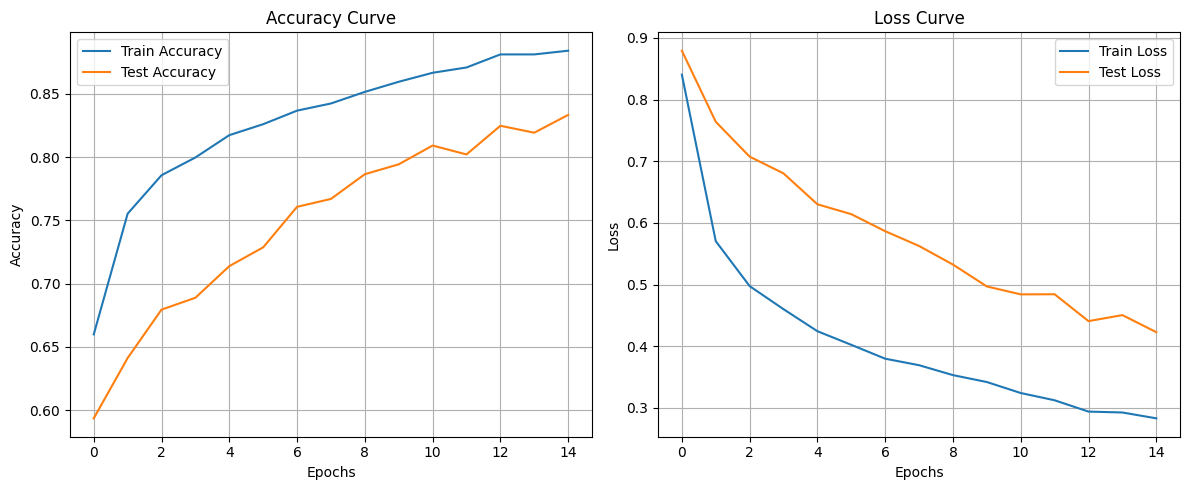

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Test Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### **FINAL ACCURACY**

In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Final Test Accuracy: {acc * 100:.2f}%")


40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 0.8565 - loss: 0.4193
Final Test Accuracy: 83.35%


### **CLASSIFICATION REPORT**

In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

print(classification_report(y_true, y_pred, target_names=["Healthy", "Demented"]))


### **CONFUSION MATRIX**

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0,1], ["Healthy", "Demented"])
plt.yticks([0,1], ["Healthy", "Demented"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


### **SAVE MODEL**

In [ ]:
model.save("/content/drive/MyDrive/Alzheimer_EfficientNet_Benchmark.h5")
print("Model saved successfully!")


Model saved successfully!
